# 토큰화와 한국어 효율

**이 노트북에서 할 일**

1. 같은 한국어 문장을 토큰화기 두 개로 나누고, 조각 목록과 토큰 수를 비교합니다.
2. 조각을 숫자 ID로 바꾸고, 토큰화기가 앞뒤에 더하는 특수 토큰을 확인합니다.
3. Ch 4 05절의 기사 글과, 같은 문장을 여러 번 이은 글의 토큰 수를 셉니다.

**준비물** — API 키는 필요 없습니다. 모델을 부르지 않으므로 모델 호출은 0번이고 비용도 들지 않습니다.
실행 시간은 1분 안팎입니다. 첫 실행에서는 Hugging Face 사이트에서 토큰화기 파일을 내려받습니다.
그래서 인터넷 연결이 필요하고, 교재 실행 컴퓨터에서 받은 파일은 합쳐 3.6MB였습니다.

Ch 4 05절이 만든 파일 `labs/part1/ch04-data-tools/data/article-text.json`을 읽습니다. 읽기만 하고 바꾸지 않습니다.

**기준 버전** — 실습 폴더에 고정한 transformers 4.56.2와 tokenizers 0.22.2를 씁니다.
토큰화기 파일도 판 번호(revision)를 고정해 받습니다. 교재 출력은 이 버전들과 Python 3.12.13으로 만들었습니다.
다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part1/ch05-llm-principles`에서 Ch 1 3절처럼 `uv sync --locked`로 환경을 만듭니다.
커널에서 이 폴더의 `.venv`를 고른 뒤 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

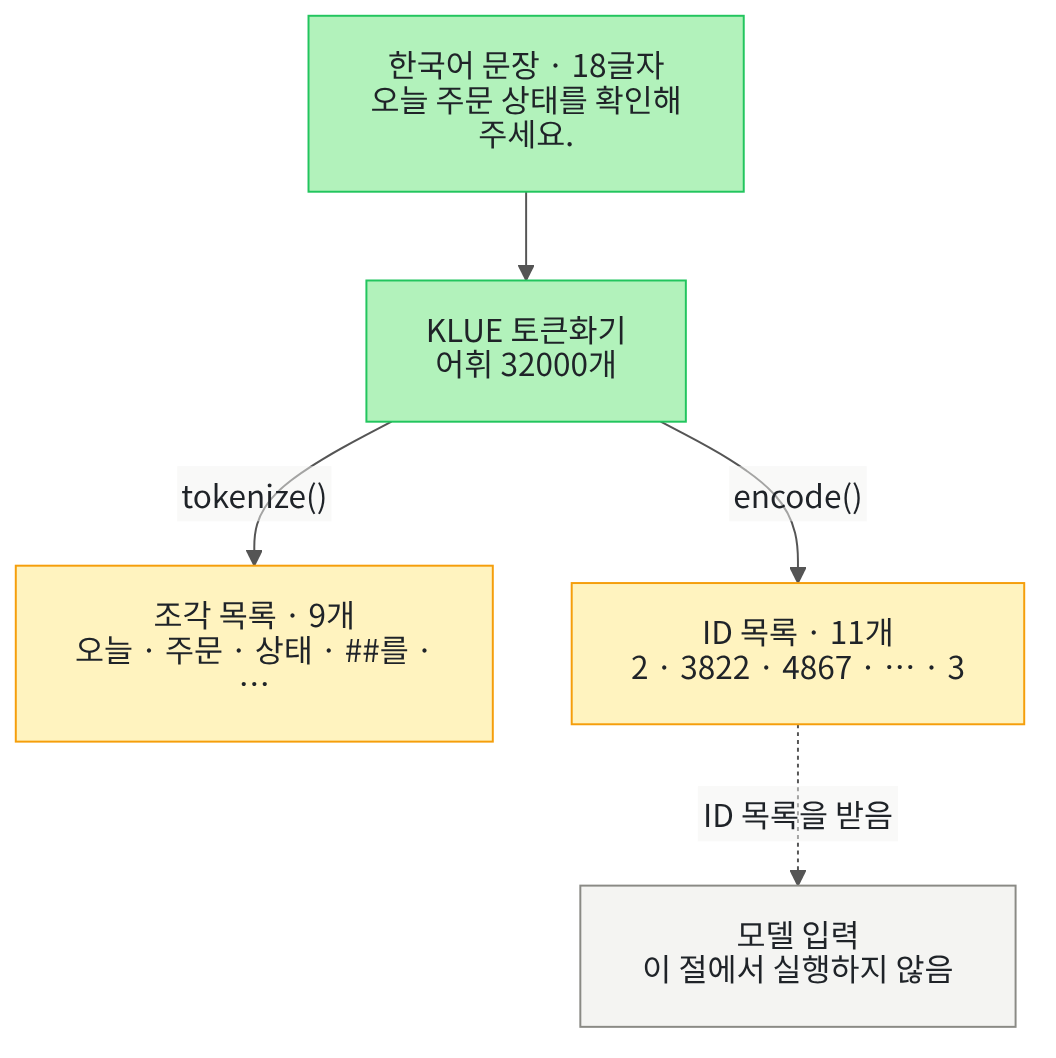

위에서 아래로 읽습니다. 초록 상자의 한국어 문장이 KLUE 토큰화기를 거쳐 노란 상자 두 개가 됩니다.
하나는 `tokenize()`가 반환한 조각 9개이고, 다른 하나는 `encode()`가 반환한 ID 11개입니다.

맨 아래 회색 상자는 ID 목록을 받는 모델입니다. 이 노트북은 모델을 부르지 않고, 토큰화기가 만든 조각과 ID까지만 봅니다.

## 1. 준비

이 절은 새 파일을 만들지 않습니다. Ch 4 05절이 실습 폴더에 남긴 기사 파일을 읽기만 하므로, 임시 폴더도 만들지 않습니다.

노트북을 `notebooks` 폴더에서 열면 Ch 4 실습 폴더는 두 칸 위 폴더 안에 있습니다. 그래서 경로를 `../../ch04-data-tools`로 시작합니다.
그 경로에 파일이 없으면 프로젝트 맨 위 폴더에서 연 경우로 보고 긴 경로를 씁니다.
함수 `os.path.exists()`는 Ch 4 05절 준비 셀에서처럼, 경로에 파일이 있으면 `True`를 반환합니다.

In [1]:
# Ch 4 05절이 만든 기사 파일의 경로를 정합니다
import os

# notebooks 폴더에서 열면 두 칸 위 폴더 안에, 프로젝트 맨 위 폴더에서 열면 긴 경로에 있습니다
article_path = "../../ch04-data-tools/data/article-text.json"
if not os.path.exists(article_path):
    article_path = "labs/part1/ch04-data-tools/data/article-text.json"
print("기사 파일이 있는가:", os.path.exists(article_path))

기사 파일이 있는가: True


**결과 읽기** — 출력 줄은 `기사 파일이 있는가: True`입니다. 이 절에서 읽을 파일을 찾았습니다.
출력이 `False`라면 Ch 4 05절 노트북을 먼저 실행해 파일을 만듭니다. 경로는 컴퓨터마다 달라서 출력하지 않았습니다.

## 2. 토큰화기 두 개 준비

모델은 글을 토큰(token)이라는 조각 단위로 다룹니다. 문장을 낱말 카드 몇 장으로 잘라 늘어놓는 일과 비슷합니다.
글을 토큰으로 나누는 도구를 토큰화기(tokenizer), 토큰화기가 가진 조각 목록을 어휘(vocabulary)라고 부릅니다.

패키지 transformers는 여러 모델의 토큰화기를 같은 방법으로 불러오게 해 줍니다.
메서드 `AutoTokenizer.from_pretrained(모델 이름, revision=판 번호)`는 토큰화기 파일을 받아 토큰화기 객체를 반환합니다.
판 번호(revision)는 같은 이름의 파일 가운데 교재가 확인한 판을 고르는 값입니다.

영어 글을 중심으로 만든 GPT-2와, 한국어 글로 만든 KLUE BERT의 토큰화기를 준비합니다. 속성 `vocab_size`는 어휘에 든 조각 종류 수입니다.
함수 `warnings.filterwarnings()` 줄은 진행 표시 위젯이 없다는 경고 한 줄을 끕니다. 실습 폴더 README에도 적힌 경고로, 계산 결과와 관계없습니다.

실행 전에 예상합니다. 두 어휘의 크기는 서로 다를 것입니다.

In [2]:
# 두 모델의 토큰화기를 고정 판 번호로 받아 만들고, 어휘 크기를 확인합니다
import warnings

# 진행 표시 위젯이 없다는 경고(TqdmWarning)는 계산과 관계없어 화면에 내지 않습니다
warnings.filterwarnings("ignore", message="IProgress not found")
import transformers
from transformers import AutoTokenizer

print("transformers 버전:", transformers.__version__)
# from_pretrained(모델 이름, revision=판 번호)는 토큰화기 파일을 받아 토큰화기 객체를 반환합니다
gpt2_revision = "607a30d783dfa663caf39e06633721c8d4cfcd7e"
gpt2 = AutoTokenizer.from_pretrained("openai-community/gpt2", revision=gpt2_revision)
klue_revision = "77c8b3d707df785034b4e50f2da5d37be5f0f546"
klue = AutoTokenizer.from_pretrained("klue/bert-base", revision=klue_revision)
# vocab_size는 어휘에 든 조각의 종류 수입니다
print("GPT-2 어휘 크기:", gpt2.vocab_size)
print("KLUE 어휘 크기:", klue.vocab_size)

transformers 버전: 4.56.2


GPT-2 어휘 크기: 50257
KLUE 어휘 크기: 32000


**결과 읽기** — 버전 줄은 `transformers 버전: 4.56.2`입니다. 어휘 크기는 GPT-2 `50257`, KLUE `32000`입니다.

첫 실행에서는 파일을 내려받는 진행 표시가 더 나올 수 있습니다. 어휘가 크다고 한국어 문장의 토큰 수가 적다고는 말할 수 없습니다.
다음 셀부터 같은 문장을 넣어 직접 비교합니다.

## 3. GPT-2 토큰화기로 한 문장 나누기

주문 상태를 묻는 한국어 문장 하나를 나눕니다. 메서드 `tokenize(글)`는 글을 조각으로 나눈 글자 목록을 반환합니다.
함수 `len()`으로 목록의 항목 수, 곧 토큰 수를 셉니다.

실행 전에 예상합니다. 낱말이 다섯 개인 문장이니, 토큰도 열 개 안팎일 것이라고 예상해 봅니다.

In [3]:
# 한국어 문장 하나를 GPT-2 토큰화기로 나눠 조각 목록과 토큰 수를 봅니다
korean_sentence = "오늘 주문 상태를 확인해 주세요."
print("글자 수:", len(korean_sentence))
# tokenize(글)는 글을 조각(토큰)으로 나눈 글자 목록을 반환합니다
gpt2_pieces = gpt2.tokenize(korean_sentence)
print("GPT-2 토큰 수:", len(gpt2_pieces))
print("GPT-2 조각 목록:", gpt2_pieces)

글자 수: 18
GPT-2 토큰 수: 39
GPT-2 조각 목록: ['ì', 'ĺ', '¤', 'ë', 'Ĭ', 'ĺ', 'Ġì', '£', '¼', 'ë', '¬', '¸', 'Ġì', 'ĥ', 'ģ', 'í', 'ĥ', 'ľ', 'ë', '¥', '¼', 'Ġ', 'í', 'Ļ', 'ķ', 'ìĿ', '¸', 'íķ', '´', 'Ġì', '£', '¼', 'ì', 'Ħ', '¸', 'ì', 'ļ', 'Ķ', '.']


**결과 읽기** — 글자 수는 `18`인데 GPT-2 토큰 수는 `39`입니다. 예상한 열 개 안팎보다 훨씬 많습니다.

조각 목록에는 `'ì'`, `'ĺ'`, `'¤'`처럼 한글이 아닌 글자가 이어집니다. 어휘에 알맞은 한글 조각이 없어, 글자를 더 작게 쪼갠 결과입니다.
조각 앞의 `Ġ` 표시는 그 조각 앞에 공백이 있었다는 뜻입니다. 다음 셀에서 조각을 글로 되돌려 봅니다.

## 4. 조각을 번호로 바꾸고 되돌리기

모델이 받는 것은 조각 글자가 아니라, 어휘에서 조각마다 붙은 번호입니다. 이 번호를 토큰 ID라고 부릅니다.
메서드 `encode(글)`는 토큰 ID 목록을, 메서드 `decode(ID 목록)`는 번호를 다시 글로 바꾼 결과를 반환합니다.

앞 세 ID는 Ch 2 03절의 슬라이싱 `[0:3]`으로 고릅니다.
실행 전에 예상합니다. 조각 세 개를 글로 되돌리면 글자 세 개가 나올 것 같습니다.

In [4]:
# 같은 문장을 GPT-2 토큰 ID 목록으로 바꾸고, 앞 세 ID만 글로 되돌려 봅니다
# encode(글)는 조각마다 붙은 번호(토큰 ID)의 목록을 반환합니다
gpt2_ids = gpt2.encode(korean_sentence)
print("GPT-2 ID 수:", len(gpt2_ids))
first_ids = gpt2_ids[0:3]
print("앞 세 ID:", first_ids)
# decode(ID 목록)는 번호를 다시 글로 바꿔 반환합니다
first_text = gpt2.decode(first_ids)
print("앞 세 ID를 글로 되돌린 결과:", first_text)

GPT-2 ID 수: 39
앞 세 ID: [168, 246, 97]
앞 세 ID를 글로 되돌린 결과: 오


**결과 읽기** — GPT-2 ID 수는 `39`로, 3절의 토큰 수와 같습니다. 앞 세 ID는 `[168, 246, 97]`이고, 이 셋을 되돌린 결과는 `오` 한 글자입니다.

예상과 달리 한글 한 글자가 조각 세 개로 나뉘었습니다. 한글 한 글자는 UTF-8 방식으로 저장하면 3바이트입니다.
GPT-2 토큰화기는 한글 글자를 이 바이트 단위까지 쪼갰습니다. 한글 13글자 가운데 11글자가 조각 세 개, 두 글자가 조각 두 개가 되어 18글자 문장이 39토큰이 되었습니다.

## 5. KLUE 토큰화기로 같은 문장 나누기

같은 문장을 한국어 글로 만든 KLUE 토큰화기에 넣습니다. 메서드 이름과 쓰는 법은 GPT-2 토큰화기와 같습니다.
실행 전에 예상합니다. 어휘에 한국어 조각이 많을 테니, 토큰 수가 39보다 훨씬 적을 것입니다.

In [5]:
# 같은 문장을 한국어 글로 만든 KLUE 토큰화기로 나눕니다
klue_pieces = klue.tokenize(korean_sentence)
print("KLUE 토큰 수:", len(klue_pieces))
print("KLUE 조각 목록:", klue_pieces)

KLUE 토큰 수: 9
KLUE 조각 목록: ['오늘', '주문', '상태', '##를', '확인', '##해', '주세', '##요', '.']


**결과 읽기** — KLUE 토큰 수는 `9`입니다. 조각 목록은 `['오늘', '주문', '상태', '##를', '확인', '##해', '주세', '##요', '.']`입니다.

낱말 오늘, 주문, 확인이 조각 하나씩으로 나왔습니다. 앞에 `##`이 붙은 조각은 앞 조각에 공백 없이 이어진다는 표시입니다.
공백 자체는 조각으로 남지 않았습니다.

## 6. 특수 토큰 확인하기

이번에는 KLUE 토큰화기로 ID 목록을 만듭니다. 메서드 `convert_ids_to_tokens(ID 목록)`는 번호마다 어휘의 조각 이름을 찾아 목록으로 반환합니다.
ID 수가 5절의 조각 수보다 몇 개 많은지도 셉니다.

실행 전에 예상합니다. GPT-2 토큰화기에서 ID 수와 토큰 수가 같았으니, 이번에도 둘 다 9일 것 같습니다.

In [6]:
# KLUE 토큰화기로 ID 목록을 만들고, 번호를 조각 이름으로 되돌려 봅니다
klue_ids = klue.encode(korean_sentence)
print("KLUE ID 목록:", klue_ids)
# convert_ids_to_tokens(ID 목록)는 번호마다 조각 이름을 찾아 목록으로 반환합니다
klue_id_pieces = klue.convert_ids_to_tokens(klue_ids)
print("번호를 조각 이름으로 바꾼 목록:", klue_id_pieces)
added_count = len(klue_ids) - len(klue_pieces)
print("조각 목록보다 많은 ID 수:", added_count)
# 더 붙는 수는 토큰화기 설정이 정한 값이라 실행할 때마다 같습니다
assert added_count == 2

KLUE ID 목록: [2, 3822, 4867, 3889, 2138, 3915, 2097, 27616, 2182, 18, 3]
번호를 조각 이름으로 바꾼 목록: ['[CLS]', '오늘', '주문', '상태', '##를', '확인', '##해', '주세', '##요', '.', '[SEP]']
조각 목록보다 많은 ID 수: 2


**결과 읽기** — ID 목록은 `[2, 3822, 4867, 3889, 2138, 3915, 2097, 27616, 2182, 18, 3]`로 11개입니다. 목록보다 많은 ID 수는 `2`입니다.

조각 이름 목록의 양 끝에 `'[CLS]'`와 `'[SEP]'`이 붙었습니다. 문장에 없던 이 두 조각을 특수 토큰(special token)이라고 부릅니다.
마트 계산대에서 손님 물건 사이에 놓는 칸막이 막대처럼, 글의 시작과 끝을 알리는 표시입니다.

메서드 `tokenize()`는 이 표시를 넣지 않고, `encode()`는 넣었습니다. GPT-2 토큰화기는 표시를 붙이지 않아 3절과 4절의 수가 39로 같았습니다.

## 7. 영어 문장으로 바꿔 보기

3~5절의 한국어 문장과 같은 뜻의 영어 문장을 두 토큰화기에 넣습니다. 바꾼 값은 문장 하나이고, 토큰화기와 메서드는 그대로입니다.
실행 전에 예상합니다. 이번에는 영어 글을 중심으로 만든 GPT-2 토큰화기의 토큰 수가 더 적을 것입니다.

In [7]:
# 같은 뜻의 영어 문장을 두 토큰화기로 나눕니다
english_sentence = "Please check today's order status."
print("글자 수:", len(english_sentence))
gpt2_english_pieces = gpt2.tokenize(english_sentence)
print("GPT-2 토큰 수:", len(gpt2_english_pieces))
print("GPT-2 조각 목록:", gpt2_english_pieces)
klue_english_pieces = klue.tokenize(english_sentence)
print("KLUE 토큰 수:", len(klue_english_pieces))
print("KLUE 조각 목록:", klue_english_pieces)

글자 수: 34
GPT-2 토큰 수: 7
GPT-2 조각 목록: ['Please', 'Ġcheck', 'Ġtoday', "'s", 'Ġorder', 'Ġstatus', '.']
KLUE 토큰 수: 15
KLUE 조각 목록: ['Pl', '##ea', '##se', 'ch', '##eck', 'to', '##day', "'", 's', 'or', '##der', 'st', '##at', '##us', '.']


**결과 읽기** — 글자 수는 `34`이고, GPT-2 토큰 수는 `7`, KLUE 토큰 수는 `15`입니다. 한국어 문장과 순서가 뒤집혔습니다.

GPT-2 조각은 `'Please'`, `'Ġcheck'`처럼 낱말 하나가 조각 하나입니다. KLUE 조각은 `'Pl'`, `'##ea'`, `'##se'`처럼 영어 낱말을 잘게 나눴습니다.
이 한 쌍에서는 어휘를 만든 글의 언어에 따라 토큰 수가 달라졌습니다.

## 8. 문장 쌍 두 개의 토큰 수

환불 기준을 알리는 문장 쌍을 하나 더해, 문장마다 두 토큰화기의 토큰 수를 한 줄씩 출력합니다.
목록 안의 튜플을 `for korean, english in sentence_pairs:`로 풀어 담는 모양은 Ch 2 03절에서 배웠습니다.

실행 전에 예상합니다. 둘째 쌍에서도 한국어는 KLUE, 영어는 GPT-2 토큰화기가 더 적은 토큰을 쓸 것입니다.

In [8]:
# 한국어·영어 문장 쌍 두 개의 토큰 수를 토큰화기별로 한 줄씩 출력합니다
sentence_pairs = [
    ("오늘 주문 상태를 확인해 주세요.", "Please check today's order status."),
    ("환불 기준은 결제일로부터 7일입니다.", "The refund period is seven days from payment."),
]
for korean, english in sentence_pairs:
    korean_gpt2 = len(gpt2.tokenize(korean))
    korean_klue = len(klue.tokenize(korean))
    english_gpt2 = len(gpt2.tokenize(english))
    english_klue = len(klue.tokenize(english))
    print("한국어 | GPT-2", korean_gpt2, "| KLUE", korean_klue, "|", korean)
    print("영어 | GPT-2", english_gpt2, "| KLUE", english_klue, "|", english)

한국어 | GPT-2 39 | KLUE 9 | 오늘 주문 상태를 확인해 주세요.
영어 | GPT-2 7 | KLUE 15 | Please check today's order status.
한국어 | GPT-2 44 | KLUE 11 | 환불 기준은 결제일로부터 7일입니다.
영어 | GPT-2 9 | KLUE 17 | The refund period is seven days from payment.


**결과 읽기** — 첫째 쌍은 한국어 `GPT-2 39 | KLUE 9`, 영어 `GPT-2 7 | KLUE 15`로 7절까지와 같습니다. 둘째 쌍은 한국어 `GPT-2 44 | KLUE 11`, 영어 `GPT-2 9 | KLUE 17`입니다.

두 쌍 모두 예상대로 한국어는 KLUE, 영어는 GPT-2 토큰화기가 더 적은 토큰을 썼습니다.
짧은 문장 네 개로 본 결과라서, 긴 글이나 다른 토큰화기에서도 같다고 볼 수는 없습니다.

## 9. Ch 4 기사 파일 읽기

이제 짧은 문장이 아니라 Ch 4 05절이 파싱한 기사 글을 나눕니다. 파일은 Ch 2 05절처럼 `with open`으로 열고 `read()`로 글을 읽습니다.

표준 라이브러리 모듈 `json`의 함수 `json.loads(글)`는 JSON 글을 딕셔너리로 바꿔 반환합니다.
Ch 4 05절의 `json.dumps()`와 반대 방향이고, 04절 `response.json()`과 같은 방향입니다. 칸 이름은 05절에서 정한 그대로 읽습니다.

실행 전에 예상합니다. 기사 번호는 `A10`이고, 기사 글은 제목과 요약 두 줄일 것입니다.

In [9]:
# Ch 4 05절이 쓴 JSON 파일을 글로 읽고, 딕셔너리로 바꿔 네 칸을 확인합니다
import json

with open(article_path, encoding="utf-8") as file:
    json_text = file.read()
# loads()는 JSON 글을 딕셔너리로 바꿔 반환합니다
article = json.loads(json_text)
print("파일 모양 이름:", article["schema_version"])
print("원본 HTML 경로:", article["source"])
record = article["record"]
print("기사 번호:", record["id"])
article_text = record["text"]
print("기사 글:")
print(article_text)
# 파일 모양 이름과 기사 번호는 Ch 4 05절이 정한 값이라 매번 같습니다
assert article["schema_version"] == "ch04-parsed-article-v1"
assert record["id"] == "A10"

파일 모양 이름: ch04-parsed-article-v1
원본 HTML 경로: labs/part1/ch04-data-tools/data/article.html
기사 번호: A10
기사 글:
골목상권 매출 회복
주말 방문객 증가로 음식점 매출이 늘었습니다.


**결과 읽기** — 파일 모양 이름은 `ch04-parsed-article-v1`, 원본 HTML 경로는 `labs/part1/ch04-data-tools/data/article.html`입니다. 기사 번호는 `A10`입니다.

라벨 줄 `기사 글:` 아래 두 줄이 기사 글입니다. 첫 줄은 제목 `골목상권 매출 회복`, 둘째 줄은 요약 `주말 방문객 증가로 음식점 매출이 늘었습니다.`입니다.
두 `assert` 줄은 멈추지 않았습니다.

## 10. 기사 글의 토큰 수

읽은 기사 글을 두 토큰화기로 나눕니다. 글자 수에는 제목과 요약 사이의 줄바꿈 한 글자도 들어갑니다.
KLUE 조각 목록은 짧아서 함께 출력합니다.

실행 전에 예상합니다. 한국어 글이니 3·5절처럼 GPT-2 토큰 수가 KLUE보다 훨씬 많을 것입니다.

In [10]:
# 기사 글의 글자 수와 두 토큰화기의 토큰 수를 셉니다
print("기사 글자 수:", len(article_text))
article_gpt2_pieces = gpt2.tokenize(article_text)
print("GPT-2 토큰 수:", len(article_gpt2_pieces))
article_klue_pieces = klue.tokenize(article_text)
print("KLUE 토큰 수:", len(article_klue_pieces))
print("KLUE 조각 목록:", article_klue_pieces)

기사 글자 수: 36
GPT-2 토큰 수: 81
KLUE 토큰 수: 17
KLUE 조각 목록: ['골목', '##상', '##권', '매출', '회복', '주말', '방문객', '증가', '##로', '음식점', '매출', '##이', '늘', '##었', '##습', '##니다', '.']


**결과 읽기** — 기사 글자 수는 `36`, GPT-2 토큰 수는 `81`, KLUE 토큰 수는 `17`입니다. 한국어 문장과 같은 방향으로, GPT-2 토큰 수가 네 배 넘게 많습니다.

KLUE 조각 목록에는 `'음식점'`처럼 낱말 하나가 한 조각인 경우가 있습니다. `'골목'`, `'##상'`, `'##권'`처럼 나뉜 경우도 섞여 있습니다.
목록에는 줄바꿈 조각이 없습니다. KLUE 토큰화기가 줄바꿈도 공백처럼 버렸기 때문입니다.

## 11. 값 바꿔 보기 — 같은 문장을 여러 번 잇기

글이 길어지면 토큰 수도 같은 비율로 늘까요? 문장 하나를 공백 한 칸씩 끼워 1·2·4·8번 이어 붙여 봅니다.
바꾸는 값은 이은 횟수 하나입니다.

안쪽 `for` 반복은 Ch 2 02절의 `range()`로 첫 문장 뒤에 공백과 문장을 `repeat - 1`번 더 붙입니다. 반복 번호 `number`는 횟수만 셉니다.
실행 전에 예상합니다. 두 토큰화기 모두 이은 횟수가 두 배가 되면 토큰 수도 정확히 두 배가 될 것입니다.

In [11]:
# 같은 문장을 공백 한 칸씩 끼워 1·2·4·8번 이은 글의 글자 수와 토큰 수를 셉니다
base_sentence = "한국어 토큰 효율을 측정합니다."
for repeat in [1, 2, 4, 8]:
    text = base_sentence
    # 첫 문장 뒤로 공백과 문장을 repeat - 1번 더 붙입니다
    for number in range(repeat - 1):
        text = text + " " + base_sentence
    gpt2_count = len(gpt2.tokenize(text))
    klue_count = len(klue.tokenize(text))
    print("반복", repeat, "| 글자", len(text), "| GPT-2", gpt2_count, "| KLUE", klue_count)

반복 1 | 글자 17 | GPT-2 37 | KLUE 8
반복 2 | 글자 35 | GPT-2 75 | KLUE 16
반복 4 | 글자 71 | GPT-2 151 | KLUE 32
반복 8 | 글자 143 | GPT-2 303 | KLUE 64


**결과 읽기** — 첫 줄은 `반복 1 | 글자 17 | GPT-2 37 | KLUE 8`, 마지막 줄은 `반복 8 | 글자 143 | GPT-2 303 | KLUE 64`입니다. KLUE 토큰 수는 `KLUE 16`, `KLUE 32`로 정확히 두 배씩 늘었습니다.

GPT-2 토큰 수는 75, 151, 303입니다. 37의 두 배, 네 배, 여덟 배보다 1, 3, 7이 많습니다.
예상과 달리 GPT-2 토큰화기는 딱 두 배가 아니었습니다. 늘어난 수는 끼워 넣은 공백 수와 같습니다.

두 번 이은 글을 두 토큰화기로 나누고, 첫 문장이 끝나는 자리의 조각을 봅니다. 위치 번호는 Ch 2 02절에서처럼 0부터 셉니다.
첫 문장 하나가 GPT-2에서는 37토큰이라 번호 36이, KLUE에서는 8토큰이라 번호 7이 첫 문장의 마지막 조각입니다.

실행 전에 예상합니다. GPT-2 조각에서는 마침표와 다음 문장 사이에 공백 조각이 따로 있을 것입니다.

In [12]:
# 두 번 이은 글에서 첫 문장이 끝나는 자리의 조각을 두 토큰화기로 봅니다
two_sentences = base_sentence + " " + base_sentence
two_gpt2_pieces = gpt2.tokenize(two_sentences)
# GPT-2 번호 36은 첫 문장의 마지막 조각, 37과 38은 그 뒤 조각입니다
print("GPT-2 번호 36~38의 조각:", two_gpt2_pieces[36:39])
two_klue_pieces = klue.tokenize(two_sentences)
# KLUE 번호 7은 첫 문장의 마지막 조각, 8은 그 뒤 조각입니다
print("KLUE 번호 7~8의 조각:", two_klue_pieces[7:9])

GPT-2 번호 36~38의 조각: ['.', 'Ġ', 'íķ']
KLUE 번호 7~8의 조각: ['.', '한국어']


**결과 읽기** — GPT-2 조각은 `['.', 'Ġ', 'íķ']`입니다. 마침표 다음의 `'Ġ'`가 공백 한 칸을 담은 조각입니다. KLUE 조각은 `['.', '한국어']`로 공백 조각이 없습니다.

11절에서 늘어난 수 1, 3, 7이 공백 수와 같으므로, 다른 이음새에서도 같은 조각이 생긴 것으로 볼 수 있습니다. 첫 이음새 말고는 조각을 출력하지 않았습니다.
글자 수에 한 숫자를 곱해 토큰 수를 어림하기 어려운 까닭입니다.

## 정리

- 토큰화기는 글을 어휘의 조각(토큰)으로 나누고, 조각마다 번호(토큰 ID)를 붙입니다. 메서드 `tokenize()`는 조각을, `encode()`는 ID를 반환합니다.
- 18글자 문장이 GPT-2 토큰화기에서 39토큰, KLUE 토큰화기에서 9토큰이었습니다. 같은 뜻의 영어 문장은 7토큰과 15토큰이었습니다.
- 토큰화기 KLUE의 `encode()`는 특수 토큰 두 개를 더했습니다. GPT-2 토큰화기는 이은 문장 사이 공백마다 조각을 더 썼습니다.

이번에는 짧은 문장 다섯 개와 기사 글 하나를 토큰화기 두 개로만 나눴습니다. 모델은 부르지 않았고, 채팅 형식으로 넣을 때 더해지는 토큰도 실행하지 않았습니다.
다음 02절에서는 문장을 뜻을 담은 숫자 목록(임베딩)으로 바꿔, 뜻이 비슷한 문장끼리 비교합니다.